#Possum Regression

In [33]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("possum.csv")

In [3]:
df.head()

,case,site,Pop,sex,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
0,1,1,Vic,m,8.0,94.1,60.4,89.0,36.0,74.5,54.5,15.2,28.0,36.0
1,2,1,Vic,f,6.0,92.5,57.6,91.5,36.5,72.5,51.2,16.0,28.5,33.0
2,3,1,Vic,f,6.0,94.0,60.0,95.5,39.0,75.4,51.9,15.5,30.0,34.0
3,4,1,Vic,f,6.0,93.2,57.1,92.0,38.0,76.1,52.2,15.2,28.0,34.0
4,5,1,Vic,f,2.0,91.5,56.3,85.5,36.0,71.0,53.2,15.1,28.5,33.0


In [7]:
for col in df.columns:
    print(df[col].value_counts())

case
1      1
2      1
77     1
76     1
75     1
      ..
32     1
31     1
30     1
29     1
104    1
Name: count, Length: 104, dtype: int64
site
1    33
7    18
2    13
5    13
6    13
3     7
4     7
Name: count, dtype: int64
Pop
other    58
Vic      46
Name: count, dtype: int64
sex
m    61
f    43
Name: count, dtype: int64
age
3.0    27
2.0    16
4.0    14
5.0    13
6.0    12
1.0    10
7.0     7
9.0     2
8.0     1
Name: count, dtype: int64
hdlngth
93.3     4
92.4     3
91.6     3
92.8     3
94.8     3
        ..
98.6     1
95.6     1
97.6     1
103.1    1
88.6     1
Name: count, Length: 71, dtype: int64
skullw
57.6    7
56.0    6
56.3    4
56.4    3
56.2    3
       ..
59.2    1
61.0    1
63.0    1
61.5    1
55.2    1
Name: count, Length: 64, dtype: int64
totlngth
89.0    10
85.0     8
84.0     7
89.5     6
91.5     5
88.0     5
88.5     4
85.5     4
81.0     4
91.0     4
86.0     4
93.0     3
82.0     3
83.0     3
80.5     3
82.5     3
90.0     3
90.5     3
92.0     3
86.5     2

In [8]:
df.describe()

,case,site,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
count,104.000000,104.000000,102.000000,104.000000,104.000000,104.000000,104.000000,103.000000,104.000000,104.000000,104.000000,104.000000
mean,52.500000,3.625000,3.833333,92.602885,56.883654,87.088462,37.009615,68.459223,48.130769,15.046154,27.000000,32.586538
std,30.166206,2.349086,1.909244,3.573349,3.113426,4.310549,1.959518,4.395306,4.109380,1.050374,2.045597,2.761949
min,1.000000,1.000000,1.000000,82.500000,50.000000,75.000000,32.000000,60.300000,40.300000,12.800000,22.000000,25.000000
25%,26.750000,1.000000,2.250000,90.675000,54.975000,84.000000,35.875000,64.600000,44.800000,14.400000,25.500000,31.000000
50%,52.500000,3.000000,3.000000,92.800000,56.350000,88.000000,37.000000,68.000000,46.800000,14.900000,27.000000,32.500000
75%,78.250000,6.000000,5.000000,94.725000,58.100000,90.000000,38.000000,72.500000,52.000000,15.725000,28.000000,34.125000
max,104.000000,7.000000,9.000000,103.100000,68.600000,96.500000,43.000000,77.900000,56.200000,17.800000,32.000000,40.000000


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   case      104 non-null    int64  
 1   site      104 non-null    int64  
 2   Pop       104 non-null    object 
 3   sex       104 non-null    object 
 4   age       102 non-null    float64
 5   hdlngth   104 non-null    float64
 6   skullw    104 non-null    float64
 7   totlngth  104 non-null    float64
 8   taill     104 non-null    float64
 9   footlgth  103 non-null    float64
 10  earconch  104 non-null    float64
 11  eye       104 non-null    float64
 12  chest     104 non-null    float64
 13  belly     104 non-null    float64
dtypes: float64(10), int64(2), object(2)
memory usage: 11.5+ KB


In [13]:
print("\n Veri Seti Eksik Değer Sayıları")
print(df.isnull().sum())
print("\n Eksik Değer Yüzdelik ")
print((df.isnull().mean()*100).round(2))
print("\n Tekrarlanan Veri")
print(df.duplicated().sum())


 Veri Seti Eksik Değer Sayıları
case        0
site        0
Pop         0
sex         0
age         2
hdlngth     0
skullw      0
totlngth    0
taill       0
footlgth    1
earconch    0
eye         0
chest       0
belly       0
dtype: int64

 Eksik Değer Yüzdelik 
case        0.00
site        0.00
Pop         0.00
sex         0.00
age         1.92
hdlngth     0.00
skullw      0.00
totlngth    0.00
taill       0.00
footlgth    0.96
earconch    0.00
eye         0.00
chest       0.00
belly       0.00
dtype: float64

 Tekrarlanan Veri
0


In [17]:
missing_row = df[df.isnull().any(axis=1)]
missing_row

,case,site,Pop,sex,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
40,41,2,Vic,f,5.0,88.4,57.0,83.0,36.5,NaN,40.3,15.9,27.0,30.5
43,44,2,Vic,m,NaN,85.1,51.5,76.0,35.5,70.3,52.6,14.4,23.0,27.0
45,46,2,Vic,m,NaN,91.4,54.4,84.0,35.0,72.8,51.2,14.4,24.5,35.0


In [26]:
for col in ["age","footlgth"]:
    print(f"\n {col} eksik:")
    df.loc[df[col].isnull().sum()]


 age eksik:

 footlgth eksik:


In [27]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
case,104.0,52.500000,30.166206,1.0,26.750,52.50,78.250,104.0
site,104.0,3.625000,2.349086,1.0,1.000,3.00,6.000,7.0
age,102.0,3.833333,1.909244,1.0,2.250,3.00,5.000,9.0
hdlngth,104.0,92.602885,3.573349,82.5,90.675,92.80,94.725,103.1
skullw,104.0,56.883654,3.113426,50.0,54.975,56.35,58.100,68.6
totlngth,104.0,87.088462,4.310549,75.0,84.000,88.00,90.000,96.5
taill,104.0,37.009615,1.959518,32.0,35.875,37.00,38.000,43.0
footlgth,103.0,68.459223,4.395306,60.3,64.600,68.00,72.500,77.9
earconch,104.0,48.130769,4.109380,40.3,44.800,46.80,52.000,56.2
eye,104.0,15.046154,1.050374,12.8,14.400,14.90,15.725,17.8


In [28]:
df.columns

Index(['case', 'site', 'Pop', 'sex', 'age', 'hdlngth', 'skullw', 'totlngth',
       'taill', 'footlgth', 'earconch', 'eye', 'chest', 'belly'],
      dtype='object')

In [30]:
print(df["Pop"].value_counts())
print(df["sex"].value_counts())
print(df["site"].value_counts())

Pop
other    58
Vic      46
Name: count, dtype: int64
sex
m    61
f    43
Name: count, dtype: int64
site
1    33
7    18
2    13
5    13
6    13
3     7
4     7
Name: count, dtype: int64


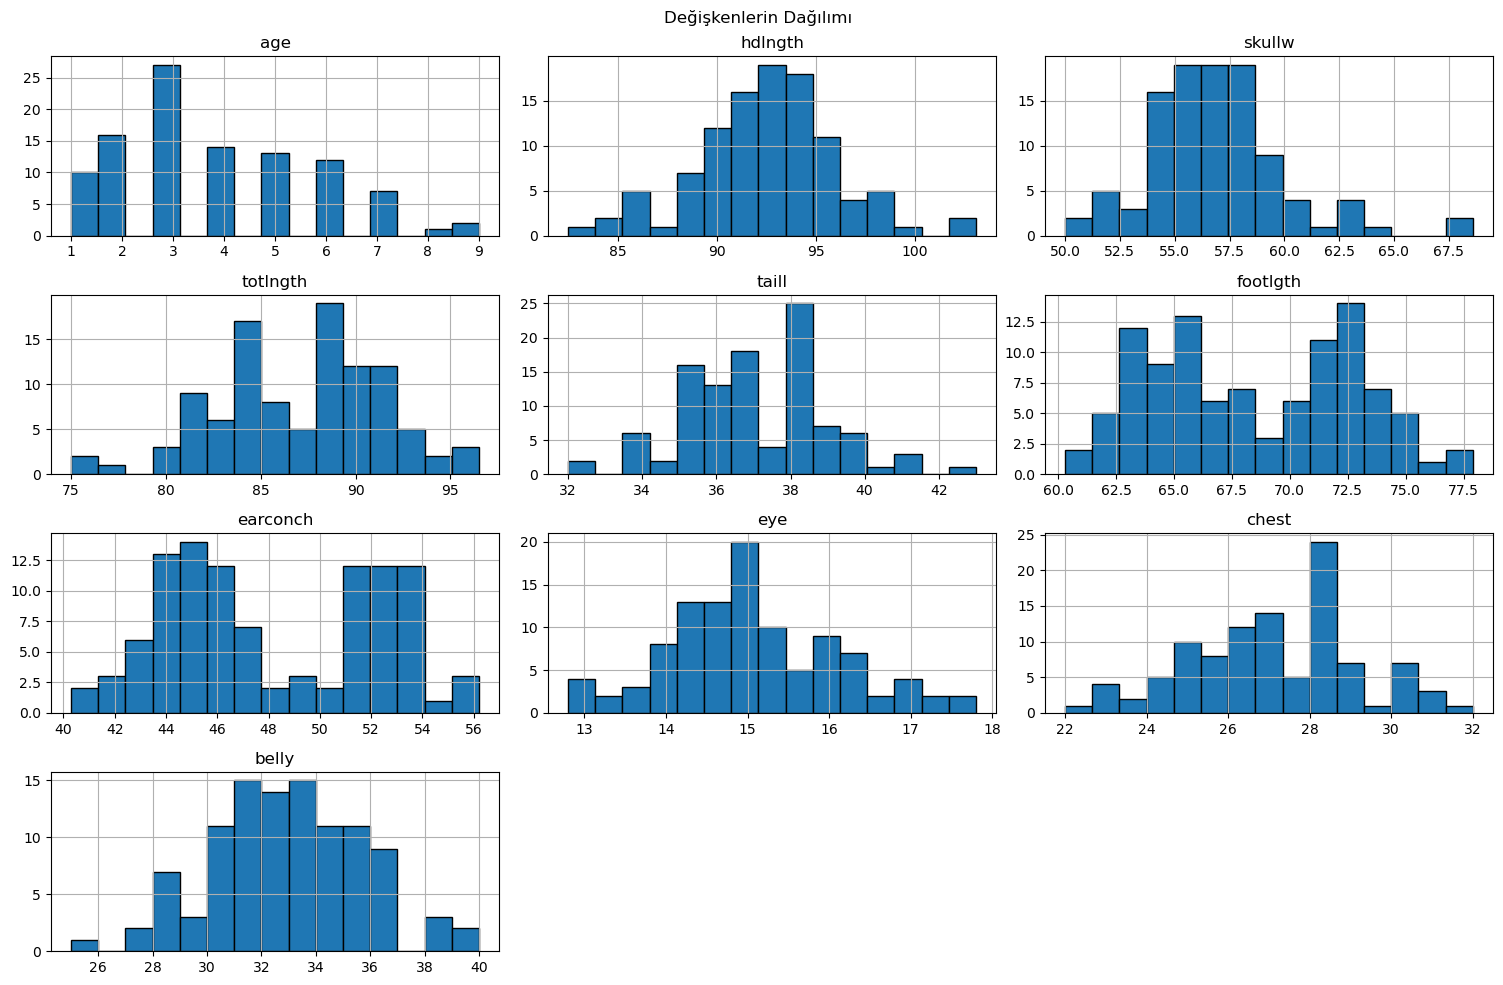

In [34]:
numeric_cols = [
    "age", "hdlngth", "skullw", "totlngth",
    "taill", "footlgth", "earconch",
    "eye", "chest", "belly"
]
df[numeric_cols].hist(
    figsize=(15,10),
    bins=15,
    edgecolor="black"
)
plt.suptitle("Değişkenlerin Dağılımı")
plt.tight_layout()
plt.show()

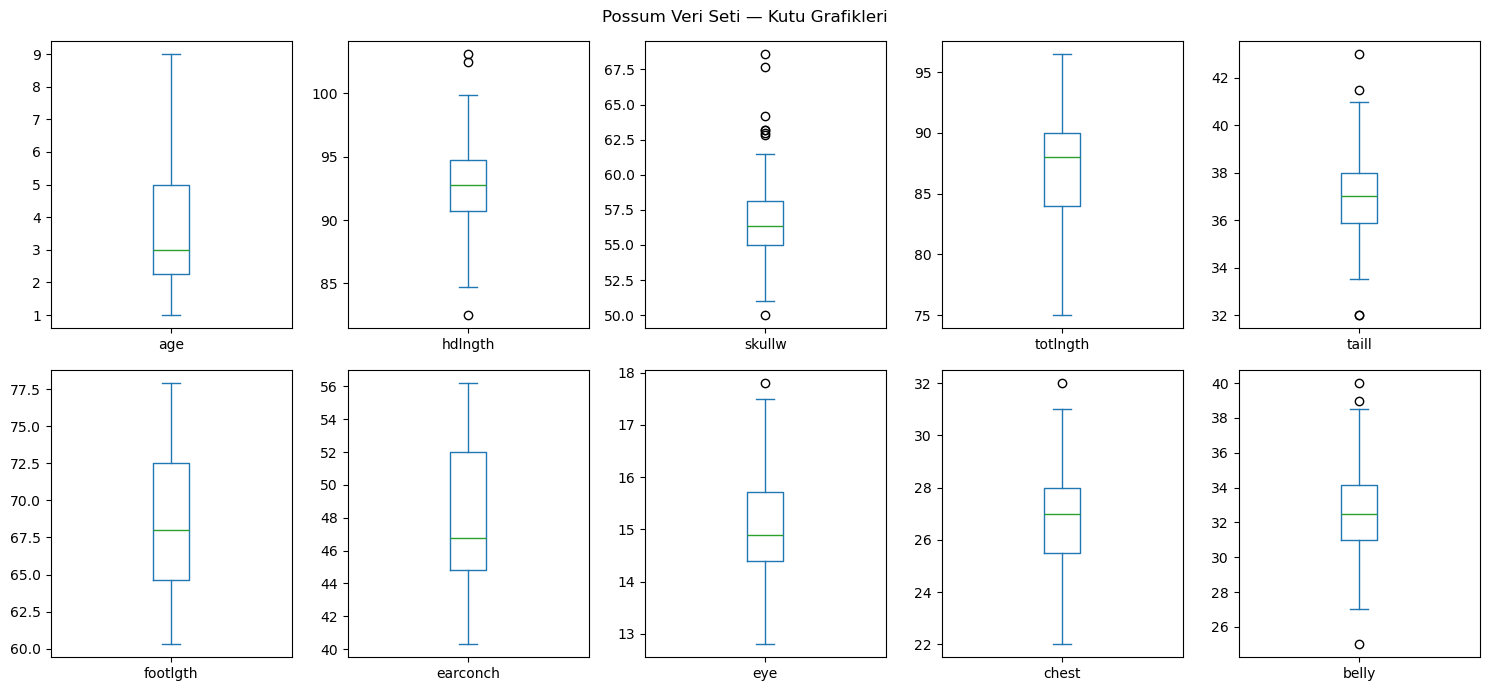

In [35]:
df[numeric_columns].plot(
    kind="box",
    subplots=True,
    layout=(2, 5),
    figsize=(15, 7),
    sharex=False,
    sharey=False
)

plt.suptitle("Possum Veri Seti — Kutu Grafikleri")
plt.tight_layout()
plt.show()


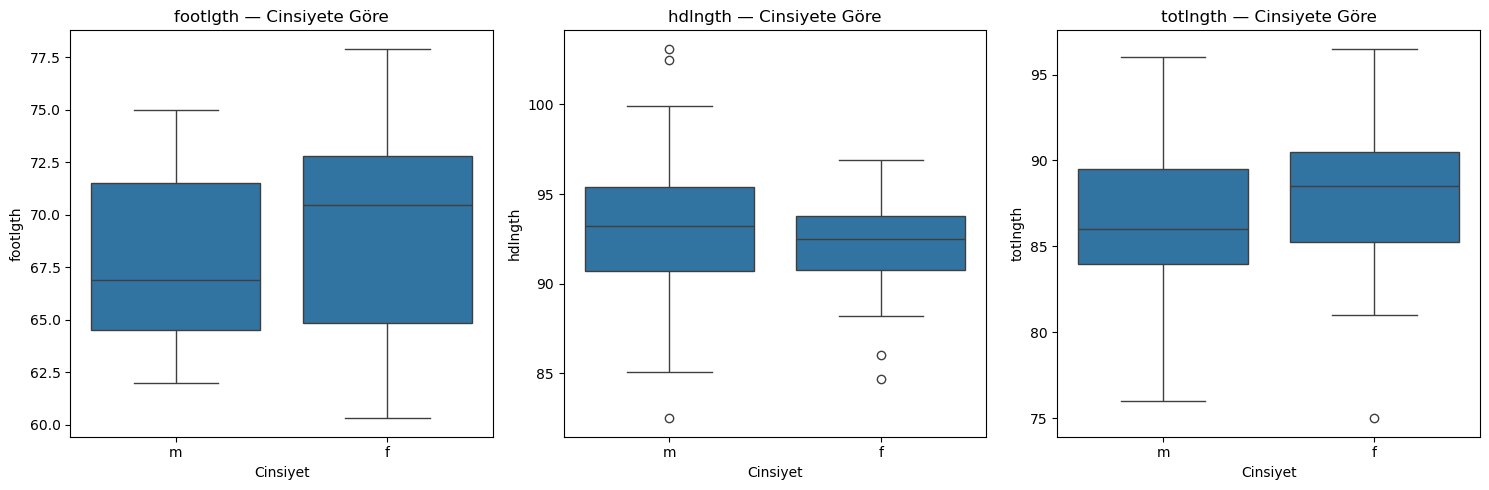

In [36]:


features_to_compare = ["footlgth", "hdlngth", "totlngth"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, column in zip(axes, features_to_compare):
    sns.boxplot(
        data=df,
        x="sex",
        y=column,
        ax=ax
    )
    ax.set_title(f"{column} — Cinsiyete Göre")
    ax.set_xlabel("Cinsiyet")
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()


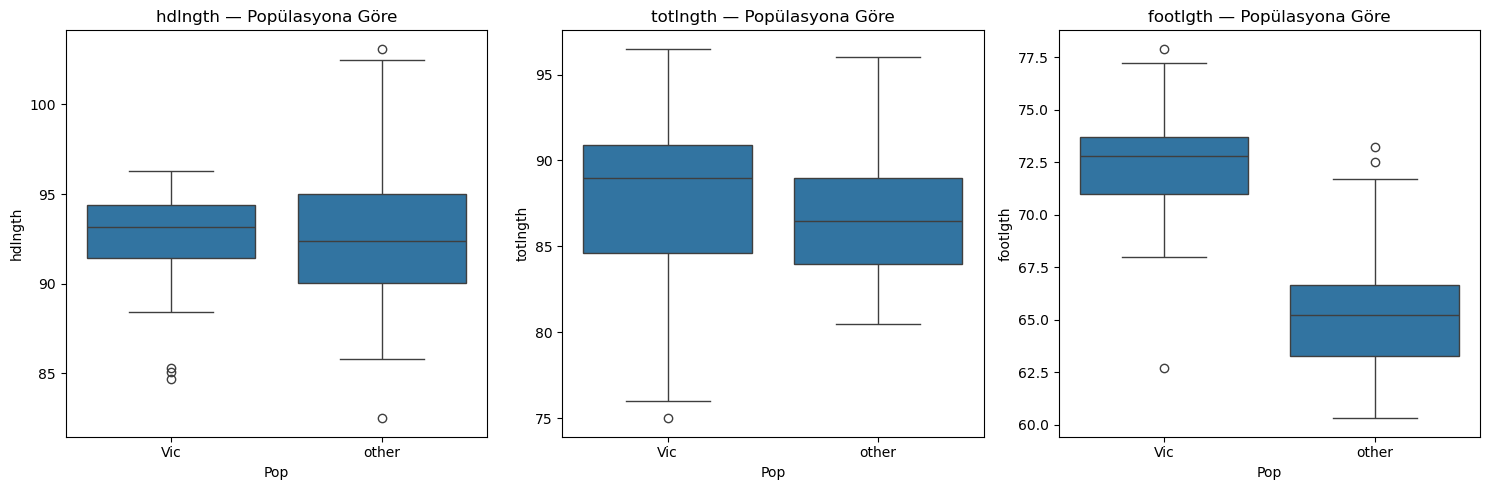

In [37]:
features_to_compare = ["hdlngth", "totlngth", "footlgth"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, column in zip(axes, features_to_compare):
    sns.boxplot(
        data=df,
        x="Pop",
        y=column,
        ax=ax
    )

    ax.set_title(f"{column} — Popülasyona Göre")

plt.tight_layout()
plt.show()

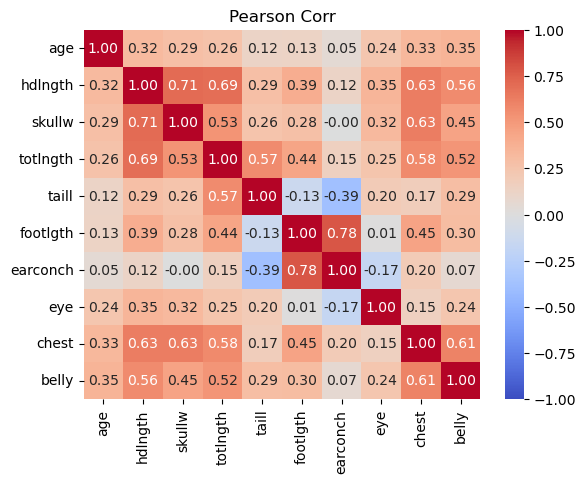

In [38]:
corr = df[numeric_columns].corr(
    method="pearson"
)
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Pearson Corr")
plt.show()

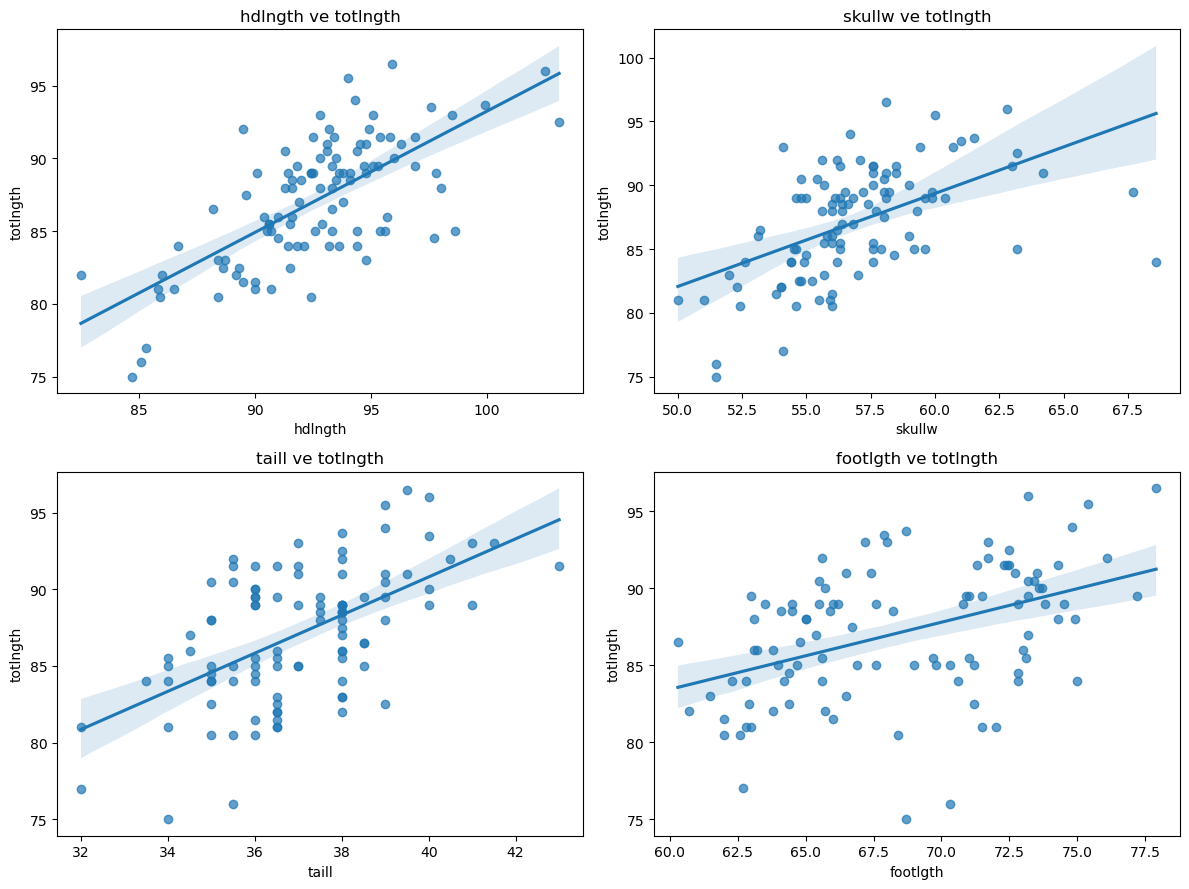

In [39]:
features = ["hdlngth", "skullw", "taill", "footlgth"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, column in zip(axes.flat, features):
    sns.regplot(
        data=df,
        x=column,
        y="totlngth",
        ax=ax,
        scatter_kws={"alpha": 0.7}
    )

    ax.set_title(f"{column} ve totlngth")

plt.tight_layout()
plt.show()

In [41]:
regression_target = "totlngth"

classification_target = "sex"

regression_features = [
    column
    for column in df.columns
    if column not in ["case", "totlngth"]
]

classification_features = [
    column
    for column in df.columns
    if column not in ["case", "sex"]
]

In [42]:
from sklearn.model_selection import train_test_split

X_reg = df[regression_features]
y_reg = df[regression_target]

X_train, X_test, y_train, y_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

In [52]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

linear_regression_model = Pipeline([
    ("preprocessor", reg_preprocessor),
    ("model", LinearRegression())
])

linear_regression_model.fit(
    X_train,
    y_train
)

linear_predictions = linear_regression_model.predict(
    X_test
)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("Linear Regression sonuçları")
print(f"MAE:  {linear_mae:.3f}")
print(f"RMSE: {linear_rmse:.3f}")
print(f"R²:   {linear_r2:.3f}")

Linear Regression sonuçları
MAE:  1.828
RMSE: 2.630
R²:   0.375


In [55]:
from sklearn.tree import DecisionTreeRegressor

tree_regression_model = Pipeline([
    ("preprocessor", reg_preprocessor),
    ("model", DecisionTreeRegressor(
        random_state=42,
        max_depth=3,
        min_samples_leaf=4
    ))
])

tree_regression_model.fit(
    X_train,
    y_train
)

tree_predictions = tree_regression_model.predict(
    X_test
)

tree_mae = mean_absolute_error(
    y_test,
    tree_predictions
)

tree_rmse = np.sqrt(
    mean_squared_error(y_test, tree_predictions)
)

tree_r2 = r2_score(
    y_test,
    tree_predictions
)

print("Decision Tree Regressor sonuçları")
print(f"MAE:  {tree_mae:.3f}")
print(f"RMSE: {tree_rmse:.3f}")
print(f"R²:   {tree_r2:.3f}")

Decision Tree Regressor sonuçları
MAE:  2.795
RMSE: 3.261
R²:   0.039


In [56]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree Regressor"
    ],
    "MAE": [
        linear_mae,
        tree_mae
    ],
    "RMSE": [
        linear_rmse,
        tree_rmse
    ],
    "R2": [
        linear_r2,
        tree_r2
    ]
})

display(
    regression_results.sort_values(
        by="MAE",
        ascending=True
    )
)

,Model,MAE,RMSE,R2
0,Linear Regression,1.827906,2.630139,0.375054
1,Decision Tree Regressor,2.795130,3.261409,0.039061


In [66]:
clf_numeric = X_train.select_dtypes(
    include=np.number
).columns.tolist()
clf_categorical = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()
clf_preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, clf_numeric),
    ("categorical", categorical_transformer, clf_categorical)
])

In [68]:
print("y_train örnek değerleri:")
print(y_train.head(10))

print("\nHedef veri tipi:")
print(y_train.dtype)

print("\nBenzersiz değer sayısı:")
print(y_train.nunique())

y_train örnek değerleri:
55    93.7
22    89.0
76    84.0
44    81.0
72    82.0
15    86.0
42    81.0
40    83.0
9     89.5
85    86.5
Name: totlngth, dtype: float64

Hedef veri tipi:
float64

Benzersiz değer sayısı:
33


In [69]:
from sklearn.model_selection import train_test_split

y_clf = df["sex"]

X_clf = df.drop(columns=["case", "sex"])

X_train, X_test, y_train, y_test = train_test_split(
    X_clf,
    y_clf,
    test_size=0.20,
    random_state=42,
    stratify=y_clf
)

print("Eğitim hedefi:")
print(y_train.value_counts())

print("\nTest hedefi:")
print(y_test.value_counts())

Eğitim hedefi:
sex
m    49
f    34
Name: count, dtype: int64

Test hedefi:
sex
m    12
f     9
Name: count, dtype: int64


Accuracy: 0.381

Sınıflandırma raporu:
              precision    recall  f1-score   support

           f       0.33      0.44      0.38         9
           m       0.44      0.33      0.38        12

    accuracy                           0.38        21
   macro avg       0.39      0.39      0.38        21
weighted avg       0.40      0.38      0.38        21



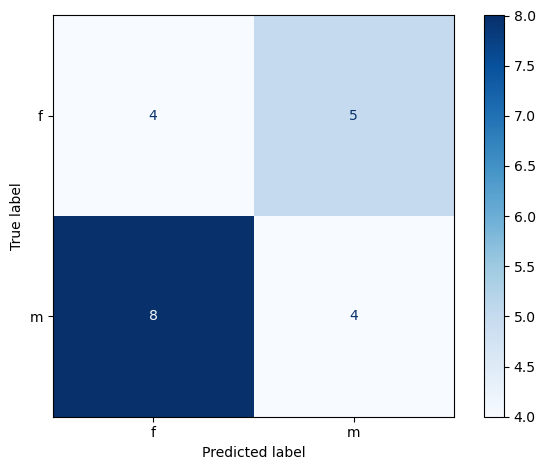

In [70]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Sayısal ve kategorik sütunları ayır
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Ön işleme
numeric_transformer = SimpleImputer(
    strategy="median"
)

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

clf_preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Model ve ön işleme tek Pipeline içinde
tree_classifier_model = Pipeline([
    ("preprocessor", clf_preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=42,
        max_depth=3,
        min_samples_leaf=4,
        class_weight="balanced"
    ))
])

# Modeli eğit
tree_classifier_model.fit(X_train, y_train)

# Tahmin üret
clf_predictions = tree_classifier_model.predict(X_test)

# Gerçek sonuçları ölç
print("Accuracy:", round(
    accuracy_score(y_test, clf_predictions), 3
))

print("\nSınıflandırma raporu:")
print(classification_report(
    y_test,
    clf_predictions,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    clf_predictions,
    labels=["f", "m"],
    display_labels=["f", "m"],
    cmap="Blues"
)

plt.tight_layout()
plt.show()

In [67]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

tree_classifier_model = Pipeline([
    ("preprocessor", clf_preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=42,
        max_depth=3,
        min_samples_leaf=4,
        class_weight="balanced"
    ))
])

tree_classifier_model.fit(
    X_train,
    y_train
)

clf_predictions = tree_classifier_model.predict(
    X_test
)





ValueError: Unknown label type: continuous. Maybe you are trying to fit a classifier, which expects discrete classes on a regression target with continuous values.

In [76]:
df.describe(include="object")

,Pop,sex
count,104,104
unique,2,2
top,other,m
freq,58,61
